In [1]:
import os

# Main project directory
PROJECT_DIR = "/content/Waste_Classification_Project"

# Create separate folders
folders = [
    "dataset",
    "notebooks",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [3]:
!pip install -q kagglehub

In [4]:
import kagglehub
import os
import shutil

download_path = kagglehub.dataset_download(
    "asdasdasasdas/garbage-classification"
)

print("Downloaded location:", download_path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Downloaded location: /kaggle/input/garbage-classification


In [5]:
print(os.listdir(download_path))

['one-indexed-files-notrash_val.txt', 'one-indexed-files-notrash_train.txt', 'Garbage classification', 'garbage classification', 'zero-indexed-files.txt', 'one-indexed-files.txt', 'one-indexed-files-notrash_test.txt']


In [6]:
def find_class_folder(path):
    required = {
        "cardboard", "glass", "metal",
        "paper", "plastic", "trash"
    }

    for root, dirs, files in os.walk(path):
        if required.issubset(set(dirs)):
            return root

    return None

source_folder = find_class_folder(download_path)

print("Class folder:", source_folder)

Class folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification


In [7]:
dataset_dir = os.path.join(PROJECT_DIR, "dataset")

if source_folder is None:
    print("Could not find the six class folders.")
else:
    for folder in os.listdir(source_folder):
        source = os.path.join(source_folder, folder)
        destination = os.path.join(dataset_dir, folder)

        if os.path.isdir(source):
            shutil.copytree(source, destination, dirs_exist_ok=True)

    print("Dataset organized successfully!")

Dataset organized successfully!


In [8]:
import os
import cv2
import matplotlib.pyplot as plt

dataset_dir = os.path.join(PROJECT_DIR, "dataset")

# Select one category
category = "plastic"

# Get image filenames
image_files = os.listdir(
    os.path.join(dataset_dir, category)
)

# Select first image
image_path = os.path.join(
    dataset_dir,
    category,
    image_files[0]
)

# Read image
image = cv2.imread(image_path)

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image shape: (384, 512, 3)
Image data type: uint8


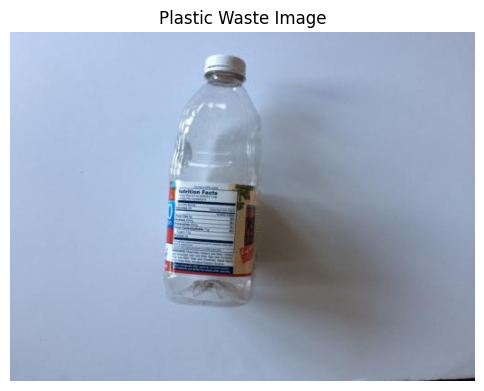

In [9]:
image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(6, 6))
plt.imshow(image_rgb)
plt.title("Plastic Waste Image")
plt.axis("off")
plt.show()

Original shape: (384, 512, 3)
Resized shape: (224, 224, 3)


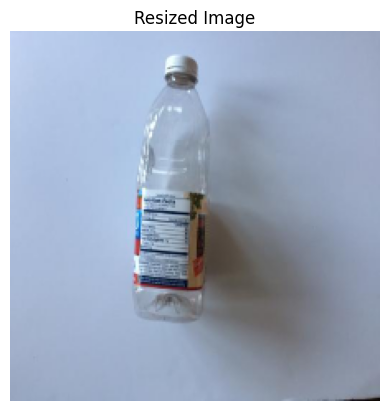

In [10]:
resized_image = cv2.resize(
    image_rgb,
    (224, 224)
)

print("Original shape:", image_rgb.shape)
print("Resized shape:", resized_image.shape)

plt.imshow(resized_image)
plt.title("Resized Image")
plt.axis("off")
plt.show()

In [11]:
normalized_image = resized_image / 255.0

print("Minimum pixel value:", normalized_image.min())
print("Maximum pixel value:", normalized_image.max())
print("Data type:", normalized_image.dtype)

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float64


In [12]:
class_names = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print(class_to_index)

{'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}


In [13]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

Found 2527 files belonging to 6 classes.
Using 1769 files for training.


In [14]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_batches = tf.data.experimental.cardinality(
    validation_dataset
)

test_dataset = validation_dataset.take(
    val_batches // 2
)

validation_dataset = validation_dataset.skip(
    val_batches // 2
)

Found 2527 files belonging to 6 classes.
Using 758 files for validation.


In [15]:
for images, labels in train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First 10 labels:", labels[:10].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [1 4 1 2 4 2 0 4 4 3]


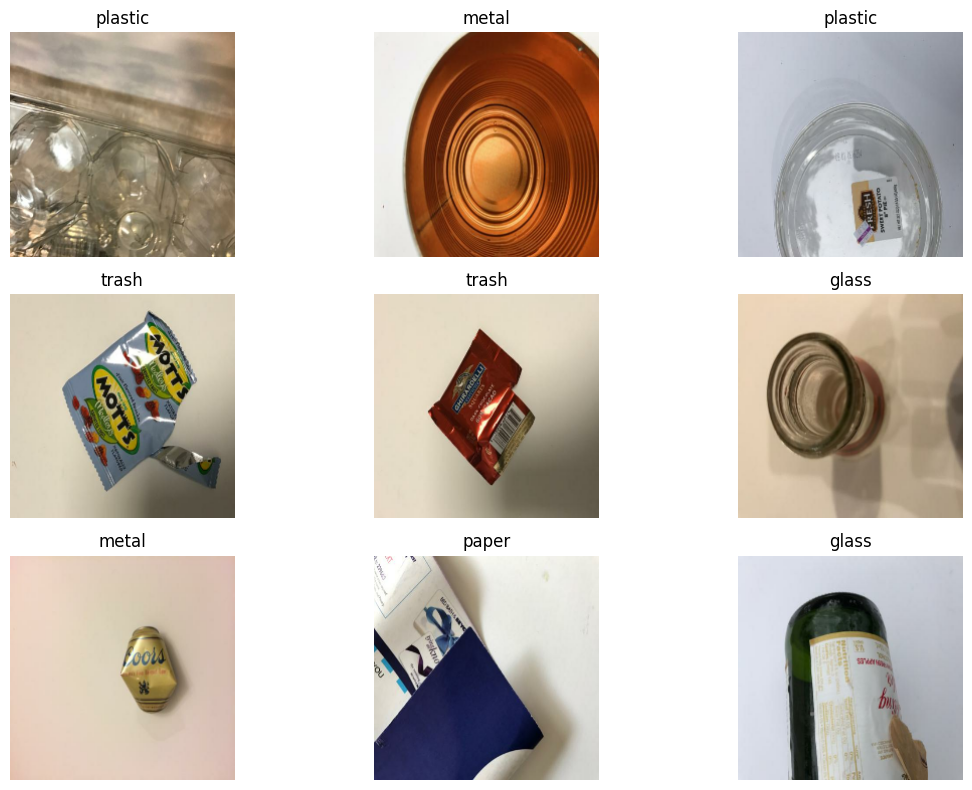

In [16]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
from tensorflow import keras
from tensorflow.keras import layers

In [18]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [19]:
base_model.trainable = False

In [20]:
inputs = keras.Input(shape=(224, 224, 3))

x = keras.applications.mobilenet_v2.preprocess_input(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    6,
    activation="softmax"
)(x)

model = keras.Model(inputs, outputs)

In [21]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [24]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 109s 2s/step - accuracy: 0.2419 - loss: 2.0042 - val_accuracy: 0.3155 - val_loss: 1.6741
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.3720 - loss: 1.6180 - val_accuracy: 0.4278 - val_loss: 1.4637
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 100s 2s/step - accuracy: 0.4522 - loss: 1.3995 - val_accuracy: 0.5348 - val_loss: 1.2616
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.5500 - loss: 1.2104 - val_accuracy: 0.5989 - val_loss: 1.1097
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.5704 - loss: 1.1142 - val_accuracy: 0.6257 - val_loss: 1.0517
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.6156 - loss: 1.0245 - val_accuracy: 0.6551 - val_loss: 0.9749
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 145s 2s/step - accuracy: 0.6507 - loss: 0.9453 - val_accuracy: 0.6898 - val_loss: 0.8779
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 0.6733 - loss: 0.9030 - val_accuracy: 0.7005 - v

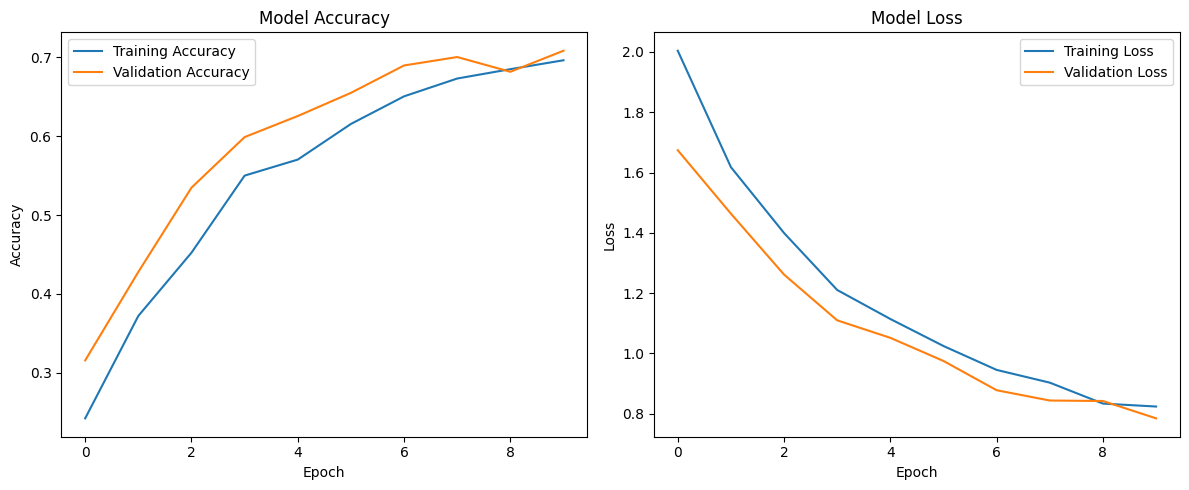

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [26]:
base_model.trainable = False

In [27]:
print("Total layers:", len(base_model.layers))

Total layers: 154


In [28]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = True

In [29]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
history_finetune = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.6371 - loss: 1.0225 - val_accuracy: 0.7380 - val_loss: 0.6963
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.7100 - loss: 0.8077 - val_accuracy: 0.7540 - val_loss: 0.6536
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.7552 - loss: 0.6938 - val_accuracy: 0.7380 - val_loss: 0.6327
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.7942 - loss: 0.5919 - val_accuracy: 0.7380 - val_loss: 0.6669
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.8157 - loss: 0.5551 - val_accuracy: 0.7647 - val_loss: 0.6002


In [31]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

12/12 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.7604 - loss: 0.6239
Test Accuracy: 0.7604166865348816
Test Loss: 0.6238769888877869


              precision    recall  f1-score   support

   cardboard       0.89      0.81      0.85        58
       glass       0.79      0.76      0.77        83
       metal       0.80      0.80      0.80        61
       paper       0.83      0.85      0.84        88
     plastic       0.68      0.80      0.74        71
       trash       0.50      0.35      0.41        23

    accuracy                           0.78       384
   macro avg       0.75      0.73      0.74       384
weighted avg       0.78      0.78      0.78       384



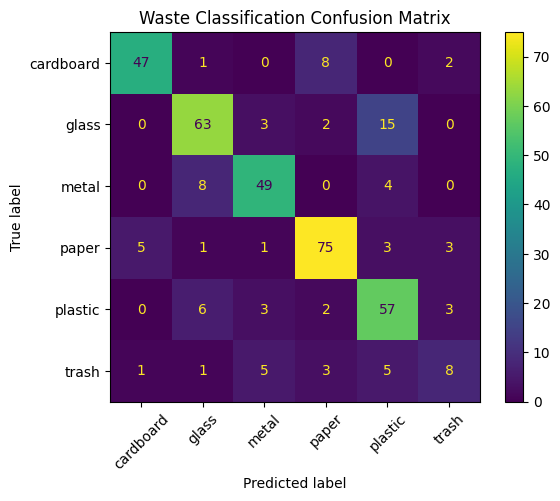

In [32]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45)
plt.title("Waste Classification Confusion Matrix")
plt.show()

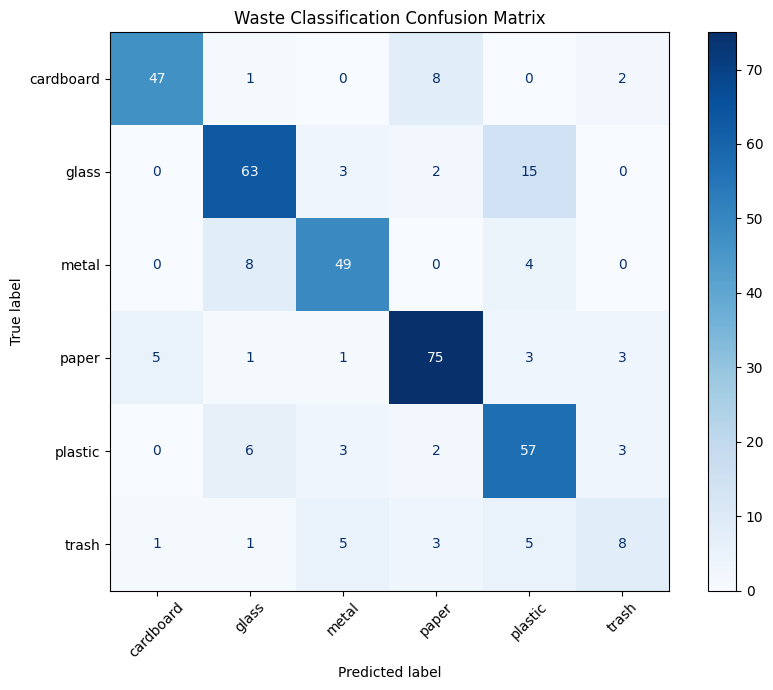

In [33]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Waste Classification Confusion Matrix")
plt.tight_layout()

results_dir = os.path.join(PROJECT_DIR, "results")
os.makedirs(results_dir, exist_ok=True)

plt.savefig(
    os.path.join(results_dir, "confusion_matrix.png"),
    bbox_inches="tight"
)

plt.show()

In [49]:
from google.colab import files

uploaded = files.upload()

Saving images (2).jfif to images (2).jfif


In [50]:
image_path = list(uploaded.keys())[0]

print("Uploaded image:", image_path)

Uploaded image: images (2).jfif


Image shape: (1, 224, 224, 3)


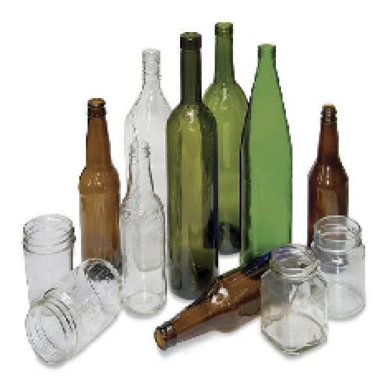

In [51]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

img = tf.keras.utils.load_img(
    image_path,
    target_size=(224, 224)
)

img_array = tf.keras.utils.img_to_array(img)

img_array = tf.expand_dims(img_array, axis=0)

print("Image shape:", img_array.shape)

plt.imshow(img)
plt.axis("off")
plt.show()

In [52]:
predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])

predicted_class = class_names[predicted_index]

confidence = predictions[0][predicted_index] * 100

print("Predicted Category:", predicted_class)
print("Confidence:", round(float(confidence), 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Predicted Category: glass
Confidence: 91.46 %


In [53]:
for i, class_name in enumerate(class_names):
    print(
        class_name,
        round(float(predictions[0][i] * 100), 2),
        "%"
    )

cardboard 1.74 %
glass 91.46 %
metal 3.24 %
paper 1.29 %
plastic 2.08 %
trash 0.2 %


In [54]:
import os

model_dir = os.path.join(PROJECT_DIR, "models")

os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(
    model_dir,
    "waste_classifier_mobilenetv2.keras"
)

print(model_path)

/content/Waste_Classification_Project/models/waste_classifier_mobilenetv2.keras


In [55]:
model.save(model_path)

print("Model saved successfully!")

Model saved successfully!


In [56]:
print("File exists:", os.path.exists(model_path))

print(
    "Model size:",
    round(os.path.getsize(model_path) / (1024 * 1024), 2),
    "MB"
)

File exists: True
Model size: 20.93 MB


In [57]:
from tensorflow import keras

loaded_model = keras.models.load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [58]:
predictions = loaded_model.predict(img_array)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


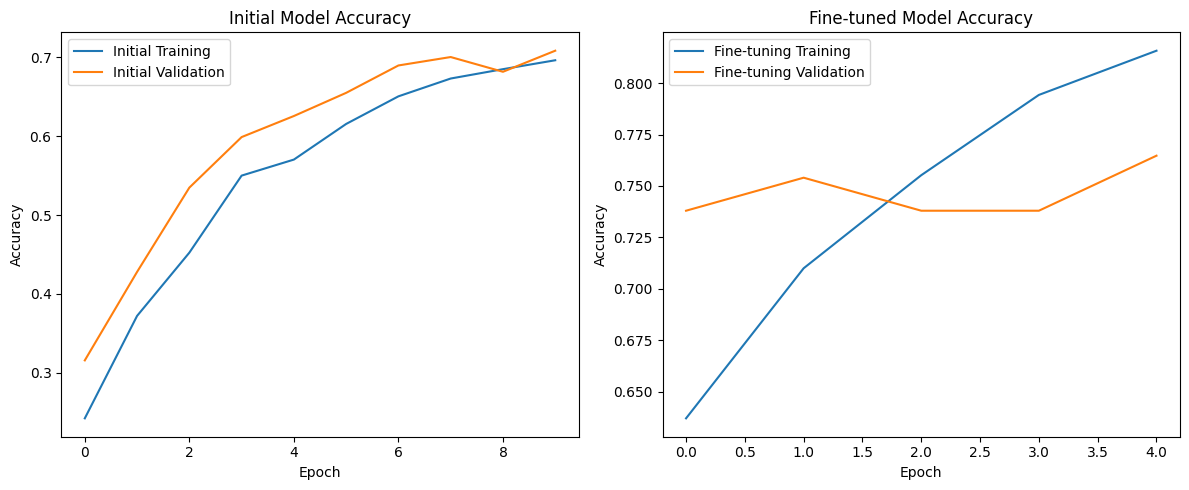

In [59]:
import matplotlib.pyplot as plt

results_dir = os.path.join(PROJECT_DIR, "results")
os.makedirs(results_dir, exist_ok=True)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Initial Training")
plt.plot(history.history["val_accuracy"], label="Initial Validation")
plt.title("Initial Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_finetune.history["accuracy"], label="Fine-tuning Training")
plt.plot(history_finetune.history["val_accuracy"], label="Fine-tuning Validation")
plt.title("Fine-tuned Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(results_dir, "training_history.png"),
    bbox_inches="tight"
)

plt.show()

In [60]:
import shutil
import os

zip_path = "/content/Waste_Classification_Project"

shutil.make_archive(
    zip_path,
    "zip",
    root_dir=PROJECT_DIR
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [61]:
from google.colab import files

files.download("/content/Waste_Classification_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>